In [ ]:
# 1. Install required libraries
!pip install -q transformers datasets accelerate evaluate librosa soundfile torchaudio

# 2. Import everything we need
import os
import glob
import numpy as np
import pandas as pd
import librosa
import torch
import torchaudio
from tqdm.notebook import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset, DatasetDict, Audio, ClassLabel
from transformers import (
    Wav2Vec2FeatureExtractor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

print("Libraries imported successfully!")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nUsing device: {device}")

if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("⚠️ No GPU detected. Training will be very slow. Go to Runtime → Change runtime type → GPU")

Libraries imported successfully!

Using device: cuda
GPU Name: Tesla T4
GPU Memory: 14.6 GB


In [ ]:
# Create main data folder
!mkdir -p /content/datasets

print("Downloading datasets... This will take a few minutes.\n")

# 1. RAVDESS (Speech only)
print("1/4 Downloading RAVDESS...")
!wget -q https://zenodo.org/record/1188976/files/Audio_Speech_Actors_01-24.zip -O /content/datasets/RAVDESS.zip
!unzip -q /content/datasets/RAVDESS.zip -d /content/datasets/RAVDESS
print("RAVDESS done!\n")

# 2. TESS
print("2/4 Downloading TESS...")
!wget -q https://www.kaggle.com/api/v1/datasets/download/ejlok1/toronto-emotional-speech-set-tess -O /content/datasets/TESS.zip
!unzip -q /content/datasets/TESS.zip -d /content/datasets/TESS
print("TESS done!\n")

# 3. CREMA-D
print("3/4 Downloading CREMA-D...")
!wget -q https://www.kaggle.com/api/v1/datasets/download/ejlok1/cremad -O /content/datasets/CREMA-D.zip
!unzip -q /content/datasets/CREMA-D.zip -d /content/datasets/CREMA-D
print("CREMA-D done!\n")

# 4. SAVEE
print("4/4 Downloading SAVEE...")
!wget -q https://www.kaggle.com/api/v1/datasets/download/barelydedicated/savee-database -O /content/datasets/SAVEE.zip
!unzip -q /content/datasets/SAVEE.zip -d /content/datasets/SAVEE
print("SAVEE done!\n")

print("="*50)
print("All downloads finished!")
print("="*50)

print("\nFolder structure:")
!ls /content/datasets/


1/4 Downloading RAVDESS...
RAVDESS done!

2/4 Downloading TESS...
TESS done!

3/4 Downloading CREMA-D...
CREMA-D done!

4/4 Downloading SAVEE...
SAVEE done!

All downloads finished!

Folder structure:
CREMA-D  CREMA-D.zip  RAVDESS  RAVDESS.zip  SAVEE  SAVEE.zip  TESS  TESS.zip


In [ ]:
print("="*60)
print("RAVDESS structure:")
print("="*60)
!ls /content/datasets/RAVDESS
print("\nSample RAVDESS files:")
!find /content/datasets/RAVDESS -name "*.wav" | head -5

print("\n" + "="*60)
print("TESS structure:")
print("="*60)
!ls /content/datasets/TESS
print("\nSample TESS files:")
!find /content/datasets/TESS -name "*.wav" | head -5

print("\n" + "="*60)
print("CREMA-D structure:")
print("="*60)
!ls /content/datasets/CREMA-D
print("\nSample CREMA-D files:")
!find /content/datasets/CREMA-D -name "*.wav" | head -5

print("\n" + "="*60)
print("SAVEE structure:")
print("="*60)
!ls /content/datasets/SAVEE
print("\nSample SAVEE files:")
!find /content/datasets/SAVEE -name "*.wav" | head -5

RAVDESS structure:
Actor_01  Actor_04  Actor_07  Actor_10	Actor_13  Actor_16  Actor_19  Actor_22
Actor_02  Actor_05  Actor_08  Actor_11	Actor_14  Actor_17  Actor_20  Actor_23
Actor_03  Actor_06  Actor_09  Actor_12	Actor_15  Actor_18  Actor_21  Actor_24

Sample RAVDESS files:
/content/datasets/RAVDESS/Actor_09/03-01-05-02-02-01-09.wav
/content/datasets/RAVDESS/Actor_09/03-01-06-02-01-02-09.wav
/content/datasets/RAVDESS/Actor_09/03-01-01-01-02-01-09.wav
/content/datasets/RAVDESS/Actor_09/03-01-08-01-02-02-09.wav
/content/datasets/RAVDESS/Actor_09/03-01-01-01-01-02-09.wav

TESS structure:
'tess toronto emotional speech set data'
'TESS Toronto emotional speech set data'

Sample TESS files:
/content/datasets/TESS/tess toronto emotional speech set data/TESS Toronto emotional speech set data/YAF_fear/YAF_cheek_fear.wav
/content/datasets/TESS/tess toronto emotional speech set data/TESS Toronto emotional speech set data/YAF_fear/YAF_calm_fear.wav
/content/datasets/TESS/tess toronto emotional sp

In [ ]:
# Unified Emotion Mapping (7 classes)
EMOTION_MAP = {
    # RAVDESS
    '01': 'neutral', '02': 'neutral',   
    '03': 'happy',   '04': 'sad',
    '05': 'angry',   '06': 'fear',
    '07': 'disgust', '08': 'surprise',

    # TESS / CREMA / SAVEE style
    'angry': 'angry', 'anger': 'angry',
    'disgust': 'disgust',
    'fear': 'fear', 'fearful': 'fear', 'fearfulness': 'fear',
    'happy': 'happy', 'happiness': 'happy',
    'neutral': 'neutral', 'calm': 'neutral',
    'sad': 'sad', 'sadness': 'sad',
    'surprise': 'surprise', 'surprised': 'surprise',
    'pleasant_surprise': 'surprise',
}

data = []

# 1. RAVDESS
print("Processing RAVDESS...")
ravdess_files = glob.glob("/content/datasets/RAVDESS/Actor_*/*.wav")

for path in tqdm(ravdess_files):
    filename = os.path.basename(path)
    parts = filename.split('-')
    emotion_code = parts[2]
    emotion = EMOTION_MAP.get(emotion_code)
    if emotion is None:
        continue
    actor = int(parts[-1].replace('.wav', ''))
    data.append({
        "path": path,
        "emotion": emotion,
        "dataset": "RAVDESS",
        "speaker": f"RAVDESS_{actor:02d}"
    })

# 2. TESS
print("\nProcessing TESS...")
tess_files = glob.glob("/content/datasets/TESS/**/*.wav", recursive=True)

for path in tqdm(tess_files):
    filename = os.path.basename(path).lower()
    if "angry" in filename or "_ang_" in filename:
        emotion = "angry"
    elif "disgust" in filename:
        emotion = "disgust"
    elif "fear" in filename:
        emotion = "fear"
    elif "happy" in filename:
        emotion = "happy"
    elif "neutral" in filename or "ps" in filename:  # ps = pleasant surprise sometimes mixed
        emotion = "neutral" if "neutral" in filename else "surprise"
    elif "sad" in filename:
        emotion = "sad"
    elif "surprise" in filename or "ps" in filename:
        emotion = "surprise"
    else:
        continue

    folder = path.split("/")[-2].lower()
    if "angry" in folder: emotion = "angry"
    elif "disgust" in folder: emotion = "disgust"
    elif "fear" in folder: emotion = "fear"
    elif "happy" in folder: emotion = "happy"
    elif "neutral" in folder: emotion = "neutral"
    elif "sad" in folder: emotion = "sad"
    elif "pleasant" in folder or "surprise" in folder or "ps" in folder: emotion = "surprise"

    speaker = "TESS_OAF" if "OAF" in path else "TESS_YAF"
    data.append({
        "path": path,
        "emotion": emotion,
        "dataset": "TESS",
        "speaker": speaker
    })

# 3. CREMA-D
print("\nProcessing CREMA-D...")
crema_files = glob.glob("/content/datasets/CREMA-D/AudioWAV/*.wav")

for path in tqdm(crema_files):
    filename = os.path.basename(path)
    parts = filename.split("_")
    emotion_code = parts[2]

    mapping = {
        "ANG": "angry",
        "DIS": "disgust",
        "FEA": "fear",
        "HAP": "happy",
        "NEU": "neutral",
        "SAD": "sad"
    }
    emotion = mapping.get(emotion_code)
    if emotion is None:
        continue

    speaker = f"CREMA_{parts[0]}"
    data.append({
        "path": path,
        "emotion": emotion,
        "dataset": "CREMA-D",
        "speaker": speaker
    })

# 4. SAVEE
print("\nProcessing SAVEE...")
savee_files = glob.glob("/content/datasets/SAVEE/AudioData/**/*.wav", recursive=True)

for path in tqdm(savee_files):
    filename = os.path.basename(path).lower()
    if filename.startswith("a"):
        emotion = "angry"
    elif filename.startswith("d"):
        emotion = "disgust"
    elif filename.startswith("f"):
        emotion = "fear"
    elif filename.startswith("h"):
        emotion = "happy"
    elif filename.startswith("n"):
        emotion = "neutral"
    elif filename.startswith("sa"):
        emotion = "sad"
    elif filename.startswith("su"):
        emotion = "surprise"
    else:
        continue

    speaker = path.split("/")[-2]  
    data.append({
        "path": path,
        "emotion": emotion,
        "dataset": "SAVEE",
        "speaker": f"SAVEE_{speaker}"
    })

# Create DataFrame
df = pd.DataFrame(data)

print("\n" + "="*50)
print("UNIFIED DATASET CREATED")
print("="*50)
print(f"Total samples: {len(df)}")
print("\nSamples per dataset:")
print(df["dataset"].value_counts())
print("\nEmotion distribution:")
print(df["emotion"].value_counts())
print("\nNumber of unique speakers:", df["speaker"].nunique())

Processing RAVDESS...


  0%|          | 0/1440 [00:00<?, ?it/s]


Processing TESS...


  0%|          | 0/5600 [00:00<?, ?it/s]


Processing CREMA-D...


  0%|          | 0/7442 [00:00<?, ?it/s]


Processing SAVEE...


  0%|          | 0/480 [00:00<?, ?it/s]


UNIFIED DATASET CREATED
Total samples: 14962

Samples per dataset:
dataset
CREMA-D    7442
TESS       5600
RAVDESS    1440
SAVEE       480
Name: count, dtype: int64

Emotion distribution:
emotion
angry       2323
fear        2323
happy       2323
disgust     2323
sad         2323
neutral     2295
surprise    1052
Name: count, dtype: int64

Number of unique speakers: 121


In [ ]:
# 1. Define the final emotion classes (ordered)
emotion_list = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
label2id = {emotion: i for i, emotion in enumerate(emotion_list)}
id2label = {i: emotion for i, emotion in enumerate(emotion_list)}

print("Label mapping:")
print(label2id)

# 2. Add numeric labels to the dataframe
df["label"] = df["emotion"].map(label2id)

# Remove any rows that failed mapping (should be 0)
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

print(f"\nFinal number of samples: {len(df)}")

# 3. Create Hugging Face Dataset
# We keep only the necessary columns
hf_dataset = Dataset.from_pandas(df[["path", "label", "speaker", "dataset"]])

# Cast the audio column
hf_dataset = hf_dataset.cast_column("path", Audio(sampling_rate=16000))

hf_dataset = hf_dataset.rename_column("path", "audio")

print("\nHugging Face Dataset created:")
print(hf_dataset)

Label mapping:
{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}

Final number of samples: 14962

Hugging Face Dataset created:
Dataset({
    features: ['audio', 'label', 'speaker', 'dataset'],
    num_rows: 14962
})


## 5. Clean the data (remove duplicate TESS files) and explore it

Removed 2800 duplicate files -> 12162 samples left

Samples per dataset:
dataset
CREMA-D    7442
TESS       2800
RAVDESS    1440
SAVEE       480
Name: count, dtype: int64

Emotion distribution:
emotion
angry       1923
fear        1923
happy       1923
disgust     1923
sad         1923
neutral     1895
surprise     652
Name: count, dtype: int64
Dataset({
    features: ['audio', 'label', 'speaker', 'dataset'],
    num_rows: 12162
})


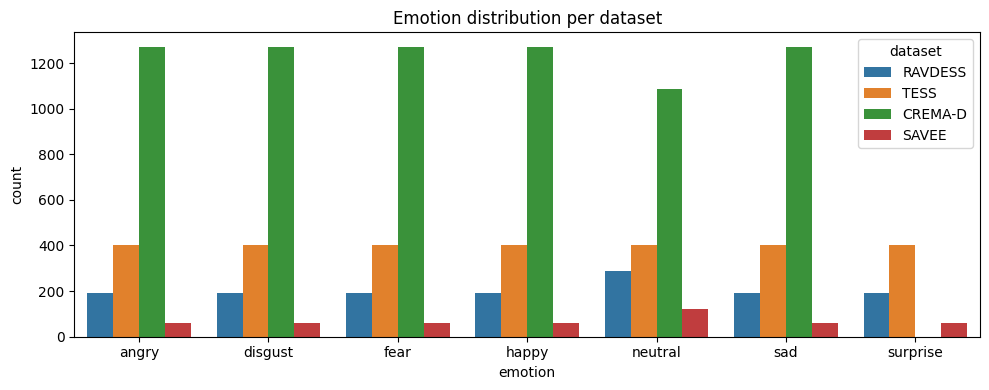

In [ ]:
# Remove duplicate files (same dataset + same file name)
df["fname"] = df["path"].apply(os.path.basename)
before = len(df)
df = df.drop_duplicates(subset=["dataset", "speaker", "fname", "emotion"]).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate files -> {len(df)} samples left")

print("\nSamples per dataset:")
print(df["dataset"].value_counts())
print("\nEmotion distribution:")
print(df["emotion"].value_counts())

# Rebuild the Hugging Face dataset from the cleaned dataframe
df["label"] = df["emotion"].map(label2id).astype(int)
hf_dataset = Dataset.from_pandas(df[["path", "label", "speaker", "dataset"]])
hf_dataset = hf_dataset.cast_column("path", Audio(sampling_rate=16000)).rename_column("path", "audio")
print(hf_dataset)

# Plots: emotion counts per dataset
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="emotion", hue="dataset", order=emotion_list)
plt.title("Emotion distribution per dataset")
plt.tight_layout()
plt.show()

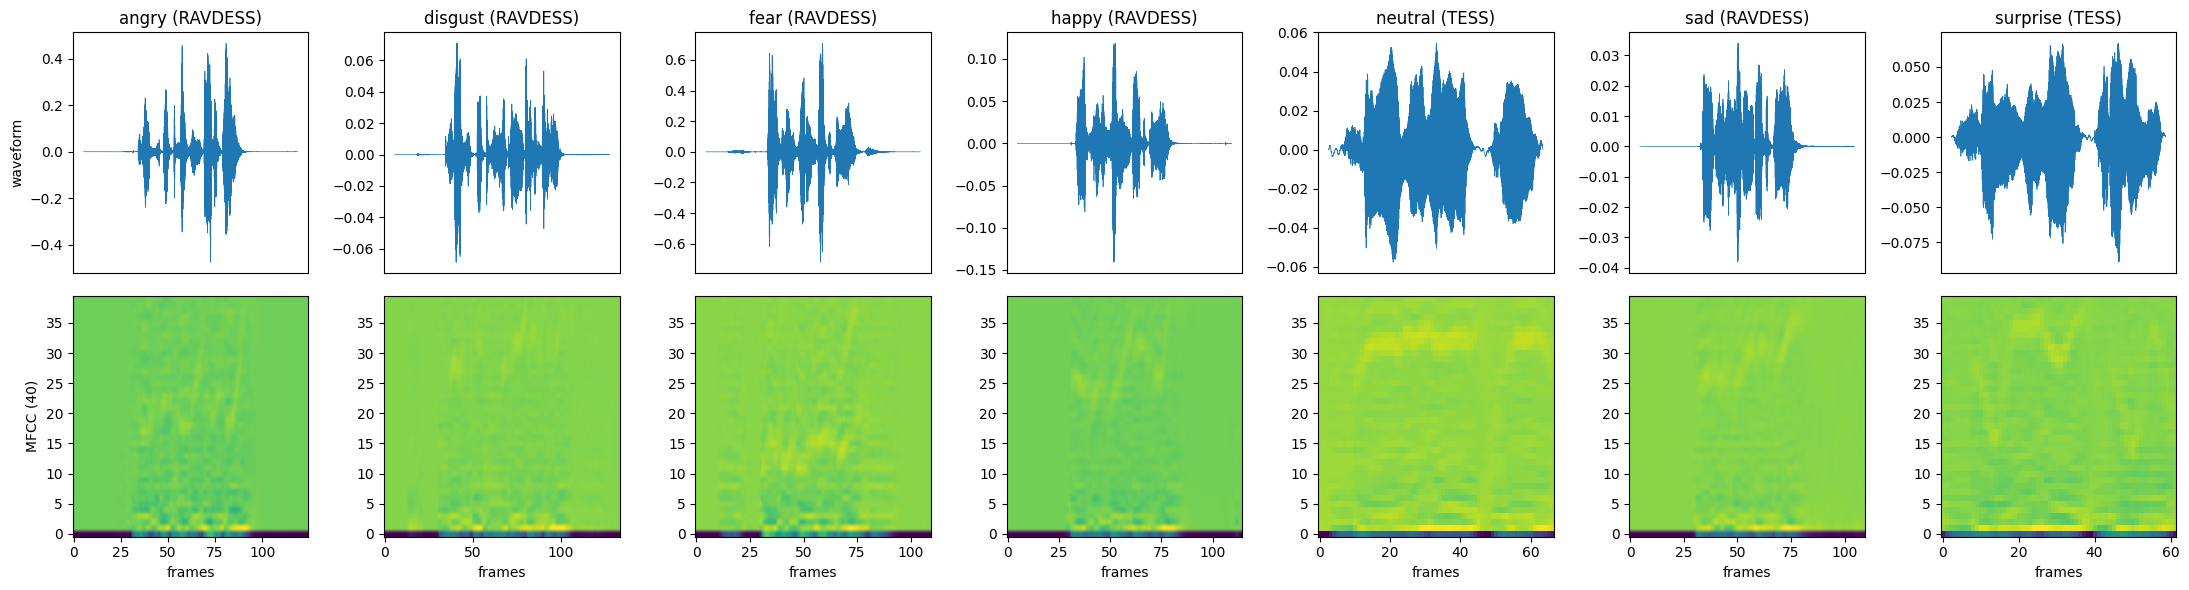

Clip length (500 random clips): mean 2.67s, 95th percentile 4.01s, max 5.91s


In [ ]:
fig, axes = plt.subplots(2, 7, figsize=(22, 6))
for i, emo in enumerate(emotion_list):
    row = df[df["emotion"] == emo].sample(1, random_state=1).iloc[0]
    y, sr = librosa.load(row["path"], sr=16000)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    axes[0, i].plot(y, linewidth=0.5)
    axes[0, i].set_title(f"{emo} ({row['dataset']})")
    axes[0, i].set_xticks([])
    axes[1, i].imshow(mfcc, aspect="auto", origin="lower")
    axes[1, i].set_xlabel("frames")
axes[0, 0].set_ylabel("waveform")
axes[1, 0].set_ylabel("MFCC (40)")
plt.tight_layout()
plt.show()

durations = [librosa.get_duration(path=p) for p in df["path"].sample(500, random_state=0)]
print(f"Clip length (500 random clips): mean {np.mean(durations):.2f}s, 95th percentile {np.percentile(durations, 95):.2f}s, max {np.max(durations):.2f}s")

## 6. Speaker-independent train / validation / test split

If the same speaker appears in both train and test, the model can partly learn who is talking instead of what emotion they express, and the accuracy looks better than it really is. So we split by speaker: no speaker appears in more than one split. The loop keeps trying seeds until every split contains all 7 emotions (surprise only exists in 3 of the 4 datasets).

In [ ]:
SEED = 42
speakers = np.array(sorted(df["speaker"].unique()))

def make_speaker_split(seed, train_frac=0.70, val_frac=0.15):
    rng = np.random.RandomState(seed)
    spk = speakers.copy()
    rng.shuffle(spk)
    n_train = int(len(spk) * train_frac)
    n_val = int(len(spk) * val_frac)
    return set(spk[:n_train]), set(spk[n_train:n_train + n_val]), set(spk[n_train + n_val:])

for seed in range(SEED, SEED + 500):
    tr_spk, va_spk, te_spk = make_speaker_split(seed)
    parts = [df[df["speaker"].isin(s)] for s in (tr_spk, va_spk, te_spk)]
    ok_classes = all(p["emotion"].nunique() == 7 for p in parts)
    sizes = np.array([len(p) for p in parts]) / len(df)
    ok_sizes = abs(sizes[0] - 0.70) < 0.05 and abs(sizes[1] - 0.15) < 0.04 and abs(sizes[2] - 0.15) < 0.04
    if ok_classes and ok_sizes:
        break
else:
    raise RuntimeError("No valid speaker split found - relax the size constraints")

print(f"Using split seed {seed}")
train_idx = df.index[df["speaker"].isin(tr_spk)].tolist()
val_idx = df.index[df["speaker"].isin(va_spk)].tolist()
test_idx = df.index[df["speaker"].isin(te_spk)].tolist()

assert not (tr_spk & va_spk) and not (tr_spk & te_spk) and not (va_spk & te_spk)
print(f"Speakers  - train {len(tr_spk)}, val {len(va_spk)}, test {len(te_spk)}")
print(f"Samples   - train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)}")

summary = pd.DataFrame({
    "train": df.loc[train_idx, "emotion"].value_counts(),
    "val": df.loc[val_idx, "emotion"].value_counts(),
    "test": df.loc[test_idx, "emotion"].value_counts(),
}).loc[emotion_list]
display(summary)
display(pd.crosstab(df["dataset"], pd.Series(
    np.where(df.index.isin(train_idx), "train", np.where(df.index.isin(val_idx), "val", "test")),
    index=df.index, name="split")))

# Class weights from the training set (helps the rarer "surprise" class)
y_train_np = df.loc[train_idx, "label"].values
class_weights = compute_class_weight("balanced", classes=np.arange(7), y=y_train_np)
print("\nClass weights:", dict(zip(emotion_list, class_weights.round(2))))

Using split seed 156
Speakers  - train 84, val 18, test 19
Samples   - train 9102, val 1508, test 1552


,train,val,test
emotion,,,
angry,1426,242,255
disgust,1426,242,255
fear,1426,242,255
happy,1426,242,255
neutral,1397,252,246
sad,1426,242,255
surprise,575,46,31


split,test,train,val
dataset,,,
CREMA-D,1312,4982,1148
RAVDESS,120,1200,120
SAVEE,120,120,240
TESS,0,2800,0



Class weights: {'angry': np.float64(0.91), 'disgust': np.float64(0.91), 'fear': np.float64(0.91), 'happy': np.float64(0.91), 'neutral': np.float64(0.93), 'sad': np.float64(0.91), 'surprise': np.float64(2.26)}


## 7. Model A - MFCC features + CNN-BiLSTM (classic approach)

This is the approach from the project description: extract MFCCs, then use a CNN to find local patterns in the spectrum and a bidirectional LSTM to model how they change over time. It is a good baseline for comparing against the pretrained Wav2Vec2 model in the next section.

In [ ]:
from joblib import Parallel, delayed
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader

SR = 16000
DURATION = 3.0                  
N_MFCC = 40
HOP = 256
N_FRAMES = int(np.ceil(SR * DURATION / HOP))   

def extract_mfcc(path):
    y, _ = librosa.load(path, sr=SR, duration=DURATION)
    y, _ = librosa.effects.trim(y, top_db=30)
    target = int(SR * DURATION)
    y = np.pad(y, (0, max(0, target - len(y))))[:target]
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, hop_length=HOP, n_fft=1024)
    delta = librosa.feature.delta(mfcc)
    feats = np.concatenate([mfcc, delta], axis=0)         
    return feats[:, :N_FRAMES].astype(np.float32)

print("Extracting MFCC features (about 2-4 minutes)...")
X_all = Parallel(n_jobs=-1)(delayed(extract_mfcc)(p) for p in tqdm(df["path"].tolist()))
X_all = np.stack(X_all)                                    
y_all = df["label"].values
print("Feature tensor:", X_all.shape)

mean = X_all[train_idx].mean(axis=(0, 2), keepdims=True)
std = X_all[train_idx].std(axis=(0, 2), keepdims=True) + 1e-6
X_all = (X_all - mean) / std

class MFCCDataset(TorchDataset):
    def __init__(self, idx, augment=False):
        self.X, self.y, self.augment = X_all[idx], y_all[idx], augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].copy()
        if self.augment:   
            t = np.random.randint(0, 20); t0 = np.random.randint(0, x.shape[1] - t)
            f = np.random.randint(0, 8);  f0 = np.random.randint(0, x.shape[0] - f)
            x[:, t0:t0 + t] = 0
            x[f0:f0 + f, :] = 0
        return torch.from_numpy(x), int(self.y[i])

train_loader = DataLoader(MFCCDataset(train_idx, augment=True), batch_size=64, shuffle=True)
val_loader = DataLoader(MFCCDataset(val_idx), batch_size=128)
test_loader = DataLoader(MFCCDataset(test_idx), batch_size=128)

Extracting MFCC features (about 2-4 minutes)...


  0%|          | 0/12162 [00:00<?, ?it/s]

Feature tensor: (12162, 80, 188)


In [ ]:
class CNNBiLSTM(nn.Module):
    def __init__(self, n_feats=2 * N_MFCC, n_classes=7):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv1d(cin, cout, kernel_size=5, padding=2),
                nn.BatchNorm1d(cout), nn.ReLU(),
                nn.MaxPool1d(2), nn.Dropout(0.25))
        self.cnn = nn.Sequential(block(n_feats, 128), block(128, 128), block(128, 256))
        self.lstm = nn.LSTM(256, 128, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.4), nn.Linear(128, n_classes))
    def forward(self, x):                    
        x = self.cnn(x)                      
        x = x.transpose(1, 2)                
        out, _ = self.lstm(x)
        return self.head(out.mean(1))        

def run_epoch(model, loader, optimizer=None, criterion=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    preds, labels, total_loss = [], [], 0.0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
                if scheduler is not None: scheduler.step()
            total_loss += loss.item() * len(yb)
            preds.append(logits.argmax(1).cpu().numpy()); labels.append(yb.cpu().numpy())
    preds, labels = np.concatenate(preds), np.concatenate(labels)
    return total_loss / len(labels), accuracy_score(labels, preds), f1_score(labels, preds, average="macro"), preds, labels

cnn_model = CNNBiLSTM().to(device)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device), label_smoothing=0.05)
optimizer = torch.optim.AdamW(cnn_model.parameters(), lr=1e-3, weight_decay=1e-2)
EPOCHS_A = 40
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=2e-3, epochs=EPOCHS_A, steps_per_epoch=len(train_loader))

history_a, best_f1, patience, wait = [], 0.0, 8, 0
for epoch in range(1, EPOCHS_A + 1):
    tr_loss, tr_acc, tr_f1, _, _ = run_epoch(cnn_model, train_loader, optimizer, criterion, scheduler)
    va_loss, va_acc, va_f1, _, _ = run_epoch(cnn_model, val_loader, None, criterion)
    history_a.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc, val_f1=va_f1))
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f}")
    if va_f1 > best_f1:
        best_f1, wait = va_f1, 0
        torch.save(cnn_model.state_dict(), "/content/best_cnn_bilstm.pt")
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping"); break

Epoch 01 | train loss 1.815 acc 0.242 | val loss 1.710 acc 0.308 macro-F1 0.226
Epoch 02 | train loss 1.411 acc 0.471 | val loss 1.668 acc 0.374 macro-F1 0.336
Epoch 03 | train loss 1.208 acc 0.565 | val loss 1.563 acc 0.467 macro-F1 0.435
Epoch 04 | train loss 1.105 acc 0.609 | val loss 1.534 acc 0.450 macro-F1 0.408
Epoch 05 | train loss 1.069 acc 0.628 | val loss 1.508 acc 0.469 macro-F1 0.412
Epoch 06 | train loss 1.017 acc 0.651 | val loss 1.428 acc 0.509 macro-F1 0.493
Epoch 07 | train loss 1.000 acc 0.662 | val loss 1.588 acc 0.463 macro-F1 0.415
Epoch 08 | train loss 0.976 acc 0.681 | val loss 1.361 acc 0.536 macro-F1 0.508
Epoch 09 | train loss 0.963 acc 0.685 | val loss 1.560 acc 0.502 macro-F1 0.452
Epoch 10 | train loss 0.929 acc 0.701 | val loss 1.523 acc 0.502 macro-F1 0.460
Epoch 11 | train loss 0.918 acc 0.703 | val loss 1.598 acc 0.482 macro-F1 0.455
Epoch 12 | train loss 0.884 acc 0.722 | val loss 1.382 acc 0.544 macro-F1 0.506
Epoch 13 | train loss 0.870 acc 0.729 | 

## 8. Model B - fine-tune Wav2Vec2 (pretrained transformer on raw audio)

Wav2Vec2 was pretrained on thousands of hours of speech, so it already "understands" voices. We add a small classification head and fine-tune it on our 7 emotions. This usually beats MFCC + CNN/LSTM by a large margin. On a free Colab T4, 8 epochs takes roughly 40-60 minutes; lower `EPOCHS` if you are short on time.

In [ ]:
MODEL_NAME = "facebook/wav2vec2-base"
MAX_SECONDS = 4.0
MAX_LEN = int(16000 * MAX_SECONDS)
EPOCHS = 8
BATCH_SIZE = 16
GRAD_ACCUM = 2
LR = 3e-5

feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)

train_ds = hf_dataset.select(train_idx)
val_ds = hf_dataset.select(val_idx)
test_ds = hf_dataset.select(test_idx)

def preprocess(batch, train=False):
    arrays = []
    for a in batch["audio"]:
        wav = a["array"].astype(np.float32)
        if len(wav) > MAX_LEN:     
            start = np.random.randint(0, len(wav) - MAX_LEN) if train else (len(wav) - MAX_LEN) // 2
            wav = wav[start:start + MAX_LEN]
        arrays.append(wav)
    out = feature_extractor(arrays, sampling_rate=16000, return_attention_mask=False)
    return {"input_values": out["input_values"], "labels": batch["label"]}

train_ds.set_transform(lambda b: preprocess(b, train=True))
val_ds.set_transform(lambda b: preprocess(b, train=False))
test_ds.set_transform(lambda b: preprocess(b, train=False))

def data_collator(features):
    batch = feature_extractor.pad(
        [{"input_values": f["input_values"]} for f in features],
        padding=True, return_tensors="pt")
    batch["labels"] = torch.tensor([f["labels"] for f in features], dtype=torch.long)
    return batch

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1": f1_score(labels, preds, average="macro")}

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(emotion_list), label2id=label2id, id2label=id2label)
model.freeze_feature_encoder()   # keep the low-level CNN frozen: faster and more stable

steps_per_epoch = int(np.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM)))
training_args = TrainingArguments(
    output_dir="/content/wav2vec2-emotion",
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    num_train_epochs=EPOCHS,
    warmup_steps=int(0.1 * steps_per_epoch * EPOCHS),
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=25,
    remove_unused_columns=False,     
    dataloader_num_workers=2,
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=feature_extractor,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer.train()

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
projector.weight             | MISSING    | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2280, training_loss=1.0416457473708873, metrics={'train_runtime': 1952.6168, 'train_samples_per_second': 37.291, 'train_steps_per_second': 1.168, 'total_flos': 2.524760996274435e+18, 'train_loss': 1.0416457473708873, 'epoch': 8.0})

## 9. Evaluate both models on the unseen test speakers

=== Model A: MFCC + CNN-BiLSTM ===
Test accuracy 0.548 | macro-F1 0.543

              precision    recall  f1-score   support

       angry      0.577     0.765     0.658       255
     disgust      0.470     0.612     0.532       255
        fear      0.555     0.455     0.500       255
       happy      0.681     0.384     0.491       255
     neutral      0.518     0.589     0.551       246
         sad      0.560     0.494     0.525       255
    surprise      0.625     0.484     0.545        31

    accuracy                          0.548      1552
   macro avg      0.569     0.540     0.543      1552
weighted avg      0.562     0.548     0.543      1552



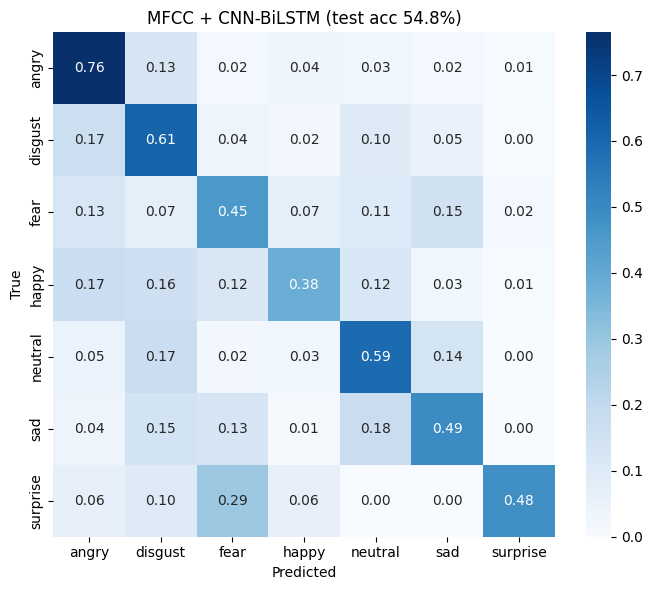


=== Model B: Wav2Vec2 ===
Test accuracy 0.692 | macro-F1 0.688

              precision    recall  f1-score   support

       angry      0.649     0.890     0.750       255
     disgust      0.712     0.573     0.635       255
        fear      0.829     0.533     0.649       255
       happy      0.812     0.659     0.727       255
     neutral      0.632     0.902     0.744       246
         sad      0.633     0.596     0.614       255
    surprise      0.657     0.742     0.697        31

    accuracy                          0.692      1552
   macro avg      0.704     0.699     0.688      1552
weighted avg      0.711     0.692     0.686      1552



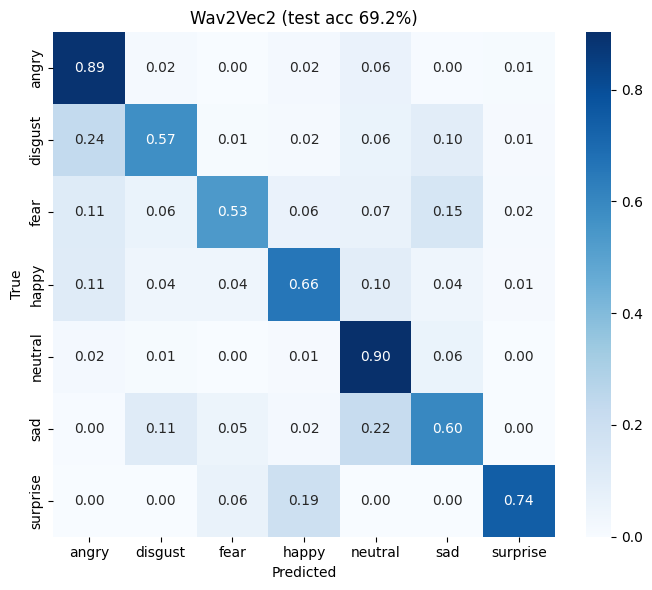


Summary


,Model,Accuracy,Macro-F1
0,MFCC + CNN-BiLSTM,0.548,0.543
1,Wav2Vec2 (fine-tuned),0.692,0.688



Accuracy per dataset (test speakers only):


,CNN-BiLSTM,Wav2Vec2
dataset,,
CREMA-D,0.572,0.691
RAVDESS,0.483,0.742
SAVEE,0.350,0.658


In [ ]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=emotion_list, yticklabels=emotion_list)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.show()

# ---- Model A: MFCC + CNN-BiLSTM
cnn_model.load_state_dict(torch.load("/content/best_cnn_bilstm.pt"))
_, acc_a, f1_a, preds_a, labels_a = run_epoch(cnn_model, test_loader, None, criterion)
print("=== Model A: MFCC + CNN-BiLSTM ===")
print(f"Test accuracy {acc_a:.3f} | macro-F1 {f1_a:.3f}\n")
print(classification_report(labels_a, preds_a, target_names=emotion_list, digits=3))
plot_confusion(labels_a, preds_a, f"MFCC + CNN-BiLSTM (test acc {acc_a:.1%})")

# ---- Model B: Wav2Vec2
pred_out = trainer.predict(test_ds)
preds_b = np.argmax(pred_out.predictions, axis=-1)
labels_b = pred_out.label_ids
acc_b, f1_b = accuracy_score(labels_b, preds_b), f1_score(labels_b, preds_b, average="macro")
print("\n=== Model B: Wav2Vec2 ===")
print(f"Test accuracy {acc_b:.3f} | macro-F1 {f1_b:.3f}\n")
print(classification_report(labels_b, preds_b, target_names=emotion_list, digits=3))
plot_confusion(labels_b, preds_b, f"Wav2Vec2 (test acc {acc_b:.1%})")

# ---- Comparison table + per-dataset accuracy
print("\nSummary")
display(pd.DataFrame({"Model": ["MFCC + CNN-BiLSTM", "Wav2Vec2 (fine-tuned)"],
                      "Accuracy": [acc_a, acc_b], "Macro-F1": [f1_a, f1_b]}).round(3))

test_df = df.loc[test_idx].reset_index(drop=True)
test_df["pred_cnn"] = preds_a
test_df["pred_w2v"] = preds_b
test_df["ok_cnn"] = test_df["pred_cnn"] == test_df["label"]
test_df["ok_w2v"] = test_df["pred_w2v"] == test_df["label"]
print("\nAccuracy per dataset (test speakers only):")
display(test_df.groupby("dataset")[["ok_cnn", "ok_w2v"]].mean().round(3).rename(columns={"ok_cnn": "CNN-BiLSTM", "ok_w2v": "Wav2Vec2"}))

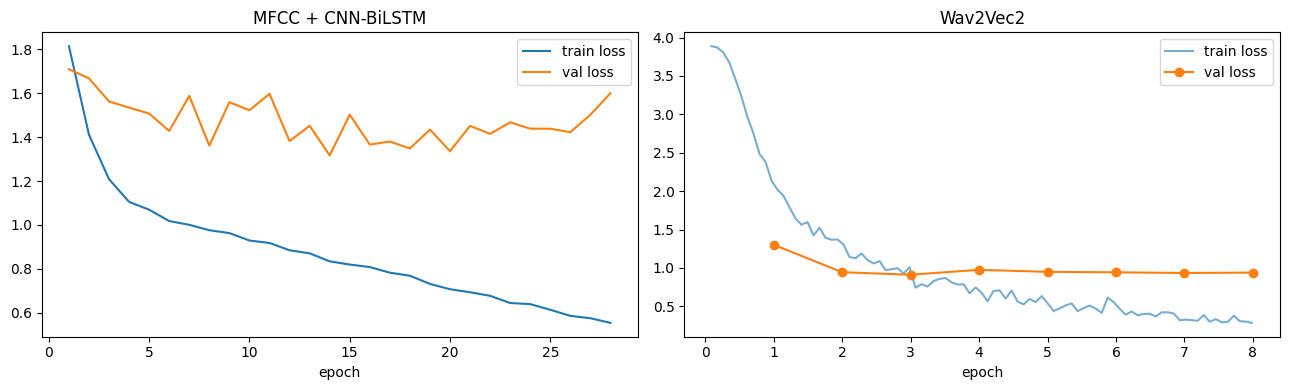

In [ ]:
# Training curves for both models
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ha = pd.DataFrame(history_a)
axes[0].plot(ha["epoch"], ha["train_loss"], label="train loss")
axes[0].plot(ha["epoch"], ha["val_loss"], label="val loss")
axes[0].set_title("MFCC + CNN-BiLSTM"); axes[0].set_xlabel("epoch"); axes[0].legend()

log = pd.DataFrame(trainer.state.log_history)
tr = log.dropna(subset=["loss"]) if "loss" in log else pd.DataFrame()
ev = log.dropna(subset=["eval_loss"])
if len(tr):
    axes[1].plot(tr["epoch"], tr["loss"], label="train loss", alpha=0.6)
axes[1].plot(ev["epoch"], ev["eval_loss"], "o-", label="val loss")
axes[1].set_title("Wav2Vec2"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 10. Try it on a new recording and save the model

`predict_emotion` works with any audio file (wav, mp3, m4a...). Upload your own recording in Colab (left sidebar, Files) and pass its path.

In [ ]:
best_model = trainer.model.eval().to(device)

def predict_emotion(audio_path, plot=True):
    wav, _ = librosa.load(audio_path, sr=16000, duration=MAX_SECONDS)
    inputs = feature_extractor(wav, sampling_rate=16000, return_tensors="pt")
    with torch.no_grad():
        logits = best_model(inputs["input_values"].to(device)).logits
    probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    if plot:
        plt.figure(figsize=(7, 3))
        plt.bar(emotion_list, probs, color=["#d62728" if i == probs.argmax() else "#9ecae1" for i in range(7)])
        plt.ylim(0, 1); plt.title(f"Predicted: {emotion_list[probs.argmax()]} ({probs.max():.0%})")
        plt.tight_layout(); plt.show()
    return emotion_list[probs.argmax()], dict(zip(emotion_list, probs.round(3)))

# Example: a few random test clips
for _, row in test_df.sample(5, random_state=7).iterrows():
    pred, _ = predict_emotion(row["path"], plot=False)
    print(f"true: {row['emotion']:9s} | predicted: {pred:9s} | {row['dataset']}")

# Example with your own file:
# print(predict_emotion("/content/my_recording.wav"))

true: fear      | predicted: fear      | RAVDESS
true: angry     | predicted: angry     | CREMA-D
true: disgust   | predicted: sad       | CREMA-D
true: neutral   | predicted: neutral   | CREMA-D
true: angry     | predicted: angry     | CREMA-D


In [ ]:
# Save the final model so you can reload it later without retraining
SAVE_DIR = "/content/emotion_wav2vec2_final"
best_model.save_pretrained(SAVE_DIR)
feature_extractor.save_pretrained(SAVE_DIR)
!zip -qr /content/emotion_wav2vec2_final.zip {SAVE_DIR}
print("Saved to", SAVE_DIR)

# Download the zip to your computer (Colab only)
try:
    from google.colab import files
    files.download("/content/emotion_wav2vec2_final.zip")
except ImportError:
    pass

# To reload later:
#   model = Wav2Vec2ForSequenceClassification.from_pretrained(SAVE_DIR)
#   feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/emotion_wav2vec2_final


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Summary and limitations (for your report)

- **Task:** 7-class speech emotion recognition (angry, disgust, fear, happy, neutral, sad, surprise) on RAVDESS, TESS, CREMA-D and SAVEE combined.
- **Features / models:** MFCC (+ delta) with a CNN-BiLSTM baseline, and a fine-tuned Wav2Vec2 transformer on raw audio.
- **Evaluation:** speaker-independent split (no speaker shared between train, validation and test), macro-F1 plus a confusion matrix.
- **Limitations:** the datasets are acted emotions recorded in quiet rooms, so accuracy on real conversations in noisy environments will be lower. TESS has only 2 speakers and SAVEE only male speakers, and "surprise" has fewer samples than the other classes (handled with class weights). Calm was merged into neutral.